# Cross-session prior persistence: opening trials 1–10

This notebook tests whether exposure to biased stimulus blocks in one session is associated with choices at the start of the next. The primary sample contains 2,140 responded trials at original positions 1–10, from 214 consecutive session pairs and 26 mice. Preprocessing excludes gaps under 12 hours; this analysis applies an upper limit of 24 hours.

Previous-session exposure, `prop_left`, is the proportion of biased trials in session $n$ occurring in left-biased blocks. It is calculated before nonresponses are removed. The outcome is left-versus-right choice in session $n+1$.

## Setup and data

Place the five preprocessing outputs in the notebook's working directory: `n1_pool.pqt`, `n_pool.pqt`, `pair_table.pqt`, `prop.pqt`, and `n_summary.pqt`.

Choice is coded as 1 for left and −1 for right. Positive signed contrast favours left, negative contrast favours right, and zero contrast provides no directional visual evidence. The saved trial pools exclude nonresponses and retain original trial positions.

Binomial mixed-effects models are fitted using mean-field variational Bayes. Fixed-effect intervals are approximate 95% variational posterior intervals (mean ± 1.96 posterior SD); hierarchical bootstrap confidence intervals are labelled separately.

In [1]:
# Imports

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from scipy import stats
from scipy.special import expit
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

In [2]:
#load data

n1_pool = pd.read_parquet("n1_pool.pqt")
n_pool = pd.read_parquet("n_pool.pqt")
pair_table = pd.read_parquet("pair_table.pqt")
prop = pd.read_parquet("prop.pqt")
n_summary = pd.read_parquet("n_summary.pqt")

## 1. Terminal-block direction and opening choices

We compared opening left-choice proportions after left-biased (`probabilityLeft = 0.8`) and right-biased (`probabilityLeft = 0.2`) terminal blocks in session $n$.

For each eligible pair, we calculated the proportion of left choices among responded trials at positions 1–10 of session $n+1$, then averaged these proportions by terminal-block direction.

In [3]:
opening = (n1_pool[n1_pool['trial_number'] <= 10]
           .groupby(level='session')['choice']
           .apply(lambda c: (c == 1).mean())
           .rename('p_left_1_10').reset_index())

d = (pair_table
     .merge(opening, left_on='session_n1', right_on='session').drop(columns='session')
     .merge(n_summary[['session','terminal_side']], left_on='session_n', right_on='session')
     .drop(columns='session'))

d24 = d[d["gap_hours"] <= 24].copy()

print(d24.groupby('terminal_side')['p_left_1_10'].agg(['mean','std','count']))

                   mean       std  count
terminal_side                           
-1             0.501087  0.238353     92
 1             0.503279  0.214335    122


Mean opening left-choice proportion was 50.33% after left-biased terminal blocks (122 pairs) and 50.11% after right-biased terminal blocks (92 pairs), a difference of 0.22 percentage points. We next compared the conditions within mice to account for unequal session contributions.

### Within-mouse comparison

We averaged opening left-choice proportions within each mouse and terminal-block condition, then used a two-sided paired t-test. Only mice contributing to both conditions were included.

In [4]:
per_mouse = d24.groupby(['subject','terminal_side'])['p_left_1_10'].mean().unstack()

per_mouse['diff'] = per_mouse[1] - per_mouse[-1]

pm = per_mouse.dropna(subset=[1, -1])

print(stats.ttest_rel(pm[1], pm[-1]))
print("mice with positive diff:", (pm['diff'] > 0).sum(), "/", len(pm))
print("Mice in paired comparison:", len(pm))

print(f"Mean P(left) after left-biased terminal blocks: {pm[1].mean():.4f}")

print(f"Mean P(left) after right-biased terminal blocks: {pm[-1].mean():.4f}")

print(f"Mean within-mouse difference: {100 * pm['diff'].mean():.2f} percentage points")

TtestResult(statistic=np.float64(1.2331960682878869), pvalue=np.float64(0.2325425515126221), df=np.int64(19))
mice with positive diff: 14 / 20
Mice in paired comparison: 20
Mean P(left) after left-biased terminal blocks: 0.5211
Mean P(left) after right-biased terminal blocks: 0.4715
Mean within-mouse difference: 4.95 percentage points


Twenty of the 26 mice contributed both conditions. Their mean opening left-choice proportions were 52.1% after left-biased and 47.2% after right-biased terminal blocks. The mean within-mouse difference was 4.95 percentage points; 14 of 20 mice showed a positive difference.

The paired comparison was not statistically significant, $t(19)=1.23$, $p=0.233$. These means give equal weight to each included mouse, whereas the preceding summary gives equal weight to each session.

## 2. Previous-session exposure and opening choices

The primary model relates previous-session `prop_left` to opening choices in the same 214 session pairs. It includes signed contrast and trial position, with random intercepts for mouse and session.

Exposure is coded as `prop_left_10 = (prop_left - 0.5) / 0.10`: one unit is a 10-percentage-point increase in exposure. The `_10` suffix denotes this scaling. Trial position is coded as `trial_c = (trial_number - 1) / 10`.

A positive exposure coefficient indicates higher odds of choosing left after greater left-biased exposure in the preceding session.

In [5]:
pairs24 = (
    d24[
        ["session_n", "session_n1", "gap_hours", "terminal_side"]
    ]
    .merge(
        prop[["session", "prop_left"]],
        left_on="session_n",
        right_on="session",
        how="left",
        validate="one_to_one"
    )
    .drop(columns="session")
)

# Trials 1–10 of session n+1, with exposure and terminal side from session n.
first10 = (
    n1_pool.reset_index()
    .loc[
        lambda x: x["trial_number"] <= 10,
        [
            "session",
            "subject",
            "trial_number",
            "choice",
            "contrast_all"
        ]
    ]
    .merge(
        pairs24[
            ["session_n1", "prop_left", "terminal_side"]
        ],
        left_on="session",
        right_on="session_n1",
        how="inner",
        validate="many_to_one"
    )
    .drop(columns="session_n1")
)

first10["chose_left"] = (first10["choice"] == 1).astype(int)

# One unit represents a 10-percentage-point difference from balanced exposure.
first10["prop_left_10"] = (first10["prop_left"] - 0.5) / 0.10

# Trial 1 = 0 and trial 10 = 0.9.
first10["trial_c"] = (first10["trial_number"] - 1) / 10

# Terminal side of session n: 1 = left-biased, 0 = right-biased.
first10["terminal_left"] = (first10["terminal_side"] == 1).astype(int)

print(
    f"{len(first10)} trials | "
    f"{first10['session'].nunique()} sessions | "
    f"{first10['subject'].nunique()} mice"
)

2140 trials | 214 sessions | 26 mice


### 2.1 Primary model

In [6]:
# Primary Bayesian binomial logistic mixed-effects model

model_first10 = BinomialBayesMixedGLM.from_formula(
    "chose_left ~ contrast_all + prop_left_10 + trial_c",
    {"subject": "0 + C(subject)", "session": "0 + C(session)"},
    first10)

result_first10 = model_first10.fit_vb()
print(result_first10.summary())

                Binomial Mixed GLM Results
             Type Post. Mean Post. SD   SD  SD (LB) SD (UB)
-----------------------------------------------------------
Intercept       M     0.1470   0.0564                      
contrast_all    M     6.2246   0.3754                      
prop_left_10    M     0.4099   0.0834                      
trial_c         M    -0.3046   0.1046                      
subject         V    -1.3417   0.1410 0.261   0.197   0.347
session         V    -0.2537   0.0483 0.776   0.704   0.855
Parameter types are mean structure (M) and variance
structure (V)
Variance parameters are modeled as log standard deviations


Previous-session left-biased exposure was positively associated with opening left choices: $\beta=0.410$ (posterior SD = 0.083; 95% variational interval [0.246, 0.573]).

Each 10-percentage-point increase in exposure corresponded to an odds ratio of 1.51 [1.28, 1.77], conditional on signed contrast, trial position, and the random effects.

### 2.2 Sensitivity to terminal-block direction

We added the terminal-block direction of session $n$ to the primary model. `terminal_left` is 1 after a left-biased terminal block and 0 after a right-biased terminal block.

In [7]:
model_first10_terminal = BinomialBayesMixedGLM.from_formula(
    "chose_left ~ contrast_all + prop_left_10 + terminal_left + trial_c",
    {"subject": "0 + C(subject)","session": "0 + C(session)"}, first10)

result_first10_terminal = model_first10_terminal.fit_vb()
print(result_first10_terminal.summary())

                 Binomial Mixed GLM Results
              Type Post. Mean Post. SD   SD  SD (LB) SD (UB)
------------------------------------------------------------
Intercept        M     0.1988   0.0564                      
contrast_all     M     6.2310   0.3757                      
prop_left_10     M     0.4222   0.0834                      
terminal_left    M    -0.0901   0.0743                      
trial_c          M    -0.3027   0.1046                      
subject          V    -1.3752   0.1411 0.253   0.191   0.335
session          V    -0.2491   0.0483 0.779   0.708   0.859
Parameter types are mean structure (M) and variance
structure (V)
Variance parameters are modeled as log standard deviations


The exposure estimate changed little after adjustment for terminal direction: $\beta=0.422$ (posterior SD = 0.083; 95% variational interval [0.259, 0.586]), compared with 0.410 in the primary model. The exposure odds ratio was 1.53 [1.30, 1.80] per 10-percentage-point increase.

The terminal-direction coefficient was $\beta=-0.090$ (posterior SD = 0.074; interval [−0.236, 0.056]), with an odds ratio of 0.91 [0.79, 1.06]. Its interval included zero.

### 2.3 Sensitivity to mouse-specific exposure slopes

We added a mouse-specific slope for `prop_left_10`, retaining mouse and session random intercepts. The intercept and slope random effects are specified as independent variance components.

In [8]:
# Random-slope extension: allow the exposure effect to vary across mice

model_first10_slope = BinomialBayesMixedGLM.from_formula(
    "chose_left ~ contrast_all + prop_left_10 + trial_c",
    {"subject_intercept": "0 + C(subject)",
     "subject_prop_slope": "0 + C(subject):prop_left_10",
     "session_intercept": "0 + C(session)"},
    first10)

result_first10_slope = model_first10_slope.fit_vb()
print(result_first10_slope.summary())

                   Binomial Mixed GLM Results
                   Type Post. Mean Post. SD   SD  SD (LB) SD (UB)
-----------------------------------------------------------------
Intercept             M     0.1471   0.0564                      
contrast_all          M     6.2281   0.3755                      
prop_left_10          M     0.4099   0.0836                      
trial_c               M    -0.3054   0.1045                      
subject_intercept     V    -1.3229   0.1409 0.266   0.201   0.353
subject_prop_slope    V    -1.7003   0.1420 0.183   0.137   0.243
session_intercept     V    -0.2771   0.0483 0.758   0.688   0.835
Parameter types are mean structure (M) and variance structure (V)
Variance parameters are modeled as log standard deviations


Allowing mouse-specific slopes left the population exposure estimate essentially unchanged: $\beta=0.410$ (posterior SD = 0.084; 95% variational interval [0.246, 0.574]), with an odds ratio of 1.51 [1.28, 1.78].

The fitted mouse-specific slope SD was 0.183 on the log-odds scale, with an approximate interval [0.137, 0.243].

### 2.4 Hierarchical bootstrap confidence intervals

We fitted 1,000 bootstrap samples, resampling mice and then sessions within each sampled mouse. All trials from a sampled session were retained together, and repeated draws received distinct mouse and session labels. The 2.5th and 97.5th percentiles define the 95% bootstrap confidence intervals.

The printed prediction summary averages over observed contrasts and trial positions, with equal weights for sessions. The figures evaluate predictions at zero contrast, with equal weights for positions 1–10. Both set mouse and session random effects to zero. The figure ribbons are pointwise intervals calculated from the bootstrap coefficients.

In [9]:
# Reusable hierarchical bootstrap for primary and zero-contrast models

def bootstrap_prediction_ci(
    model_formula,
    random_effects,
    data,
    prop_grid,
    prediction_terms,
    n_bootstrap=1000,
    rng=None,
    exposure_term="prop_left_10",
    exposure_center=0.5,
    exposure_scale=0.10,
    fixed_prediction_values=None
):
    """Resample mice and sessions, refit, and return percentile intervals and coefficients."""
    if rng is None:
        rng = np.random.default_rng(42)

    if fixed_prediction_values is None:
        fixed_prediction_values = {}

    required_columns = {
        "subject",
        "session",
        exposure_term,
        *prediction_terms
    }

    missing_columns = required_columns.difference(data.columns)

    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    subjects = data["subject"].unique()
    n_subjects = len(subjects)

    # Convert the raw prop_left grid to the model scale.
    exposure_grid = ((np.asarray(prop_grid) - exposure_center) / exposure_scale)

    reference_sessions = data["session"].to_numpy()

    bootstrap_predictions = np.full((n_bootstrap, len(prop_grid)), np.nan)

    bootstrap_betas = np.full(n_bootstrap, np.nan)
    fixed_effect_rows = []

    for bootstrap_index in range(n_bootstrap):

        if bootstrap_index % 25 == 0:
            print(f"Running bootstrap sample {bootstrap_index}/{n_bootstrap}")

        # Level 1: sample mice.
        sampled_subjects = rng.choice(subjects,size=n_subjects, replace=True)

        sampled_chunks = []

        for subject_draw, subject in enumerate(sampled_subjects):

            subject_data = data[data["subject"] == subject]

            sessions = subject_data["session"].unique()

            # Level 2: sample sessions within the selected mouse.
            sampled_sessions = rng.choice(sessions, size=len(sessions), replace=True)

            for session_draw, session in enumerate(sampled_sessions):

                # Retain every trial belonging to the sampled session.
                chunk = subject_data[subject_data["session"] == session].copy()

                # Repeated bootstrap draws need unique cluster labels.
                chunk["subject"] = (
                    f"boot_subject_{subject_draw}"
                )

                chunk["session"] = (
                    f"boot_subject_{subject_draw}"
                    f"_session_{session_draw}"
                )

                sampled_chunks.append(chunk)

        bootstrap_data = pd.concat(sampled_chunks, ignore_index= True)

        try:
            bootstrap_model = (BinomialBayesMixedGLM.from_formula(model_formula, random_effects, bootstrap_data))

            bootstrap_result = bootstrap_model.fit_vb()

            if not bootstrap_result.optim_retvals["success"]:
                raise RuntimeError(
                    "VB fit did not converge: "
                    f"{bootstrap_result.optim_retvals['message']}"
                )

            bootstrap_coef = dict(zip(bootstrap_model.exog_names, bootstrap_result.fe_mean))

            reference_linear_predictor = np.full(len(data), bootstrap_coef["Intercept"], dtype=float)

            for term in prediction_terms:

                if term in fixed_prediction_values:
                    term_values = np.full(len(data), fixed_prediction_values[term], dtype=float)
                else:
                    term_values = data[term].to_numpy()

                reference_linear_predictor += (bootstrap_coef[term] * term_values)

            linear_predictor = (reference_linear_predictor[:, None] + bootstrap_coef[exposure_term] * exposure_grid[None, :])

            trial_predictions = pd.DataFrame(expit(linear_predictor))

            trial_predictions["session"] = reference_sessions

            # Average trials within sessions, then sessions equally.
            session_predictions = (trial_predictions.groupby("session", sort=False).mean())

            bootstrap_predictions[bootstrap_index] = (session_predictions.mean(axis=0).to_numpy())

            bootstrap_betas[bootstrap_index] = (bootstrap_coef[exposure_term])

            fixed_effect_rows.append({"bootstrap_index": bootstrap_index, **bootstrap_coef})

        except Exception as error:
            print(
                f"Bootstrap {bootstrap_index} failed: {error}"
            )

    valid = ~np.isnan(bootstrap_predictions).any(axis=1)

    valid_predictions = bootstrap_predictions[valid]
    valid_betas = bootstrap_betas[valid]

    if len(valid_predictions) == 0:raise RuntimeError("All hierarchical bootstrap model fits failed.")

    ci_low = np.quantile(valid_predictions, 0.025, axis=0)

    ci_median = np.quantile( valid_predictions, 0.50,axis=0)

    ci_high = np.quantile(valid_predictions,0.975, axis=0)

    bootstrap_fixed_effects = pd.DataFrame(fixed_effect_rows)

    return (
        ci_low,
        ci_median,
        ci_high,
        valid_predictions,
        valid_betas,
        bootstrap_fixed_effects
    )

In [10]:
# Run the hierarchical bootstrap for the primary first-10 model

primary_prop_grid = np.linspace(
    first10["prop_left"].min(),
    first10["prop_left"].max(),
    100
)

primary_n_bootstrap = 1000

(
    primary_ci_low,
    primary_ci_median,
    primary_ci_high,
    primary_boot_predictions,
    primary_boot_betas,
    primary_boot_fe
) = bootstrap_prediction_ci(
    model_formula=(
        "chose_left ~ contrast_all + prop_left_10 + trial_c"
    ),
    random_effects={
        "subject": "0 + C(subject)",
        "session": "0 + C(session)"
    },
    data=first10,
    prop_grid=primary_prop_grid,

    # Average predictions over the observed contrast and trial positions.
    prediction_terms=["contrast_all", "trial_c"],

    n_bootstrap=primary_n_bootstrap,
    rng=np.random.default_rng(42)
)


# Index closest to balanced previous-session exposure
primary_balanced_index = np.argmin(np.abs(primary_prop_grid - 0.5))


print(f"Valid bootstrap fits: {len(primary_boot_betas)}/{primary_n_bootstrap}")

print(
    "Prediction 95% CI "
    "(averaged over observed contrasts and trial positions) at "    f"prop_left = "
    f"{primary_prop_grid[primary_balanced_index]:.3f}: "
    f"["
    f"{primary_ci_low[primary_balanced_index]:.3f}, "
    f"{primary_ci_high[primary_balanced_index]:.3f}"
    f"]"
)

print(
    "prop_left_10 coefficient bootstrap 95% CI: "
    f"[{np.quantile(primary_boot_betas, 0.025):.3f}, "
    f"{np.quantile(primary_boot_betas, 0.975):.3f}]"
)

Running bootstrap sample 0/1000
Running bootstrap sample 25/1000
Running bootstrap sample 50/1000
Running bootstrap sample 75/1000
Running bootstrap sample 100/1000
Running bootstrap sample 125/1000
Running bootstrap sample 150/1000
Running bootstrap sample 175/1000
Running bootstrap sample 200/1000
Running bootstrap sample 225/1000
Running bootstrap sample 250/1000
Running bootstrap sample 275/1000
Running bootstrap sample 300/1000
Running bootstrap sample 325/1000
Running bootstrap sample 350/1000
Running bootstrap sample 375/1000
Running bootstrap sample 400/1000
Running bootstrap sample 425/1000
Running bootstrap sample 450/1000
Running bootstrap sample 475/1000
Running bootstrap sample 500/1000
Running bootstrap sample 525/1000
Running bootstrap sample 550/1000
Running bootstrap sample 575/1000
Running bootstrap sample 600/1000
Running bootstrap sample 625/1000
Running bootstrap sample 650/1000
Running bootstrap sample 675/1000
Running bootstrap sample 700/1000
Running bootstrap s

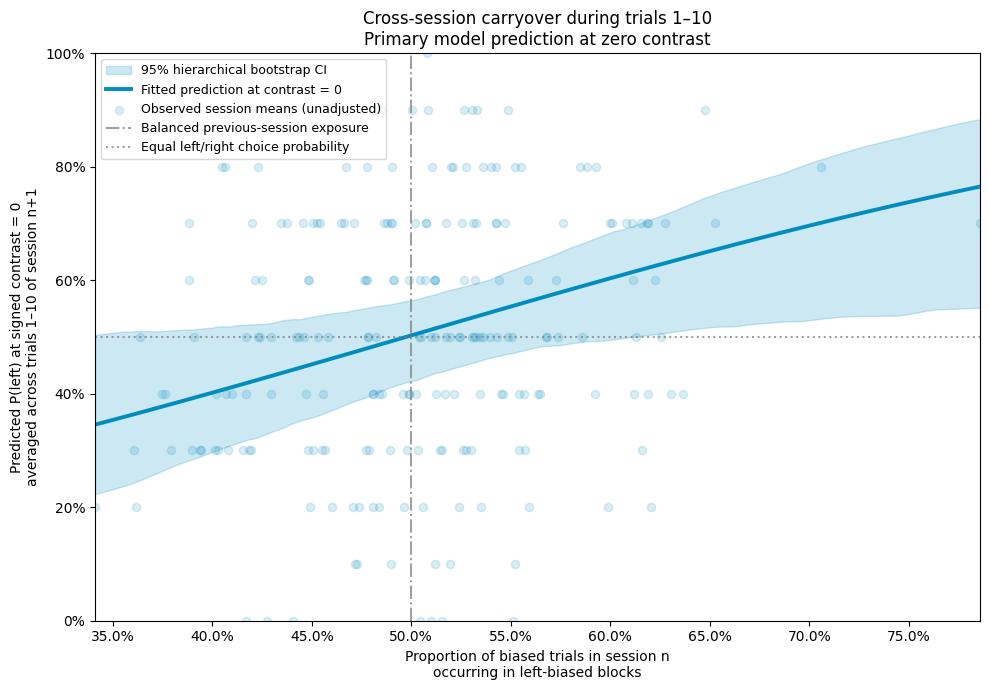

HIERARCHICAL BOOTSTRAP PREDICTION SUMMARY
Prediction contrast:     0
Trial positions:         1–10, equally weighted
Bootstrap fits used:     1000
Central 90% exposure:    0.393–0.619
Predicted P(left):       39.5%–62.2%
Probability difference:  22.7 pp
CI width at midpoint:    0.153
Bootstrap beta median:   0.415
Bootstrap beta 95% CI:   0.067 to 0.717


In [11]:
# Primary model fitted to all first-10 trials:
# predictions at zero contrast, averaged across trial positions 1–10

def predict_first10_mean_from_coef(coef,prop_grid,contrast_value=0.0):
    """Predict at fixed contrast, averaging positions 1–10 with random effects set to zero."""
    prop_grid = np.asarray(prop_grid, dtype=float)
    exposure_grid = (prop_grid - 0.5) / 0.10

    # Same scaling used when fitting the first-10 models.
    trial_c_values = (np.arange(1, 11) - 1) / 10

    linear_predictor = (
        coef["Intercept"]
        + coef["prop_left_10"] * exposure_grid[None, :]
        + coef["trial_c"] * trial_c_values[:, None]
        + coef.get("contrast_all", 0.0) * contrast_value
    )

    return expit(linear_predictor).mean(axis=0)


def build_full_bootstrap_prediction_ci(boot_fe,prop_grid,contrast_value=0.0):
    """Build pointwise intervals from saved bootstrap coefficients."""
    required_terms = ["Intercept", "prop_left_10", "trial_c"]

    coefficient_columns = required_terms.copy()
    if "contrast_all" in boot_fe.columns:
        coefficient_columns.append("contrast_all")

    # Keep only rows with finite coefficients.
    valid_rows = np.isfinite(boot_fe[coefficient_columns].to_numpy(dtype=float)).all(axis=1)

    valid_boot_fe = boot_fe.loc[valid_rows].copy()

    if valid_boot_fe.empty:
        raise ValueError("No valid bootstrap coefficients are available.")

    boot_predictions = np.stack([
        predict_first10_mean_from_coef(
            coef=row,
            prop_grid=prop_grid,
            contrast_value=contrast_value
        )
        for _, row in valid_boot_fe.iterrows()
    ])

    ci_low, ci_median, ci_high = np.quantile(
        boot_predictions,
        [0.025, 0.50, 0.975],
        axis=0
    )

    return (
        ci_low,
        ci_median,
        ci_high,
        boot_predictions,
        valid_boot_fe
    )


def plot_full_bootstrap_ci(
    result,
    model,
    data,
    boot_fe,
    prop_grid,
    contrast_value=0.0,
    color="#008CBF",
    title="Cross-session carryover: primary first-10 model",
    save_path=None,
    show_bootstrap_median=False,
    show_observed_sessions=True
):
    """Plot the fitted curve and bootstrap interval at a fixed contrast."""
    prop_grid = np.asarray(prop_grid, dtype=float)

    coef = pd.Series(
        result.fe_mean,
        index=model.exog_names
    )

    fitted_curve = predict_first10_mean_from_coef(coef=coef,prop_grid=prop_grid,contrast_value=contrast_value)

    (
        ci_low,
        ci_median,
        ci_high,
        boot_predictions,
        valid_boot_fe
    ) = build_full_bootstrap_prediction_ci(
        boot_fe=boot_fe,
        prop_grid=prop_grid,
        contrast_value=contrast_value
    )

    session_actual = (data.groupby("session").agg(prop_left=("prop_left", "first"),actual_p_left=("chose_left", "mean")).reset_index())

    central_low, central_high = (session_actual["prop_left"].quantile([0.05, 0.95]))

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.fill_between(
        prop_grid,
        ci_low,
        ci_high,
        color=color,
        alpha=0.20,
        label="95% hierarchical bootstrap CI"
    )

    if show_bootstrap_median:
        ax.plot(
            prop_grid,
            ci_median,
            color=color,
            linestyle="--",
            linewidth=2,
            alpha=0.60,
            label="Bootstrap median prediction"
        )

    ax.plot(
        prop_grid,
        fitted_curve,
        color=color,
        linewidth=2.8,
        label=f"Fitted prediction at contrast = {contrast_value:g}"
    )

    if show_observed_sessions:
        ax.scatter(
            session_actual["prop_left"],
            session_actual["actual_p_left"],
            color=color,
            s=35,
            alpha=0.15,
            label="Observed session means (unadjusted)"
        )

    ax.axvline(
        0.5,
        color="grey",
        linestyle="-.",
        linewidth=1.5,
        alpha=0.75,
        label="Balanced previous-session exposure"
    )

    ax.axhline(
        0.5,
        color="grey",
        linestyle=":",
        linewidth=1.5,
        alpha=0.75,
        label="Equal left/right choice probability"
    )

    ax.set_xlabel(
        "Proportion of biased trials in session n\n"
        "occurring in left-biased blocks"
    )

    ax.set_ylabel(
        f"Predicted P(left) at signed contrast = {contrast_value:g}\n"
        "averaged across trials 1–10 of session n+1"
    )

    ax.set_title(title)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlim(prop_grid.min(), prop_grid.max())
    ax.set_ylim(0, 1)
    ax.legend(loc="upper left", fontsize=9)

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

    # Summarize predictions across the central 90% exposure range.
    predicted_low = np.interp(central_low, prop_grid, fitted_curve)

    predicted_high = np.interp(central_high, prop_grid, fitted_curve)

    midpoint_index = len(prop_grid) // 2
    boot_betas = valid_boot_fe["prop_left_10"].to_numpy()

    print("HIERARCHICAL BOOTSTRAP PREDICTION SUMMARY")
    print(f"Prediction contrast:     {contrast_value:g}")
    print("Trial positions:         1–10, equally weighted")
    print(f"Bootstrap fits used:     {len(boot_predictions)}")
    print(
        f"Central 90% exposure:    "
        f"{central_low:.3f}–{central_high:.3f}"
    )
    print(
        f"Predicted P(left):       "
        f"{predicted_low:.1%}–{predicted_high:.1%}"
    )
    print(
        f"Probability difference:  "
        f"{100 * (predicted_high - predicted_low):.1f} pp"
    )
    print(
        f"CI width at midpoint:    "
        f"{ci_high[midpoint_index] - ci_low[midpoint_index]:.3f}"
    )
    print(f"Bootstrap beta median:   {np.median(boot_betas):.3f}")
    print(
        f"Bootstrap beta 95% CI:   "
        f"{np.quantile(boot_betas, 0.025):.3f} to "
        f"{np.quantile(boot_betas, 0.975):.3f}"
    )

    return fig, ax, {
        "fitted_curve": fitted_curve,
        "ci_low": ci_low,
        "ci_median": ci_median,
        "ci_high": ci_high,
        "boot_predictions": boot_predictions,
        "session_actual": session_actual,
        "contrast_value": contrast_value
    }


# Primary model: fitted to all contrasts, plotted at zero contrast

primary_fig, primary_ax, primary_plot_data = plot_full_bootstrap_ci(
    result=result_first10,
    model=model_first10,
    data=first10,
    boot_fe=primary_boot_fe,
    prop_grid=primary_prop_grid,
    contrast_value=0.0,
    color="#008CBF",
    title=(
        "Cross-session carryover during trials 1–10\n"
        "Primary model prediction at zero contrast"
    ),
    save_path="cross_session_prior_persistence_first10_zero_contrast.png",
    show_bootstrap_median=False,
    show_observed_sessions=True
)

All 1,000 fits were retained. The bootstrap exposure coefficient had a median of 0.415 and a 95% confidence interval [0.067, 0.717].

Across the central 90% of session-level exposure values (`prop_left` = 0.393–0.619), the primary model's predicted P(left) at zero contrast increased from 39.5% to 62.2%, a difference of 22.7 percentage points. The plotted dots are unadjusted session means across all contrasts.

The separately printed prediction interval [0.446, 0.541] at `prop_left` ≈ 0.498 uses the observed contrasts and trial positions.

## 3. Zero-contrast trials within positions 1–10

The zero-contrast subset contains 385 trials from 179 sessions and all 26 mice. Thirty-five eligible sessions had no zero-contrast trials in this window.

The model includes previous-session exposure and trial position, with mouse and session random intercepts. Scaling is unchanged. Signed contrast is omitted because it is zero for every included trial.

In [12]:
# How many zero-contrast trials occur within trials 1–10?

zc10 = first10.loc[first10["contrast_all"] == 0].copy()

zc10_counts = zc10.groupby("session").size()

print(zc10_counts.describe())
print("Median zero-contrast trials per contributing session:",zc10_counts.median())

print("Primary trials:", len(first10))
print("Zero-contrast trials:", len(zc10))
print("Input contains only zero contrast:", (zc10["contrast_all"] == 0).all())

count    179.000000
mean       2.150838
std        1.134067
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        6.000000
dtype: float64
Median zero-contrast trials per contributing session: 2.0
Primary trials: 2140
Zero-contrast trials: 385
Input contains only zero contrast: True


In [13]:
# Zero-contrast model: trials at positions 1–10
# Uses the same eligible sessions and predictor scaling as the primary model.

zc_trials = zc10.copy()

assert zc_trials["choice"].isin([-1, 1]).all()
assert zc_trials["prop_left"].notna().all()

print(f"Zero-contrast trials: {len(zc_trials)}")
print(f"Contributing sessions: {zc_trials['session'].nunique()}")
print(f"Contributing mice: {zc_trials['subject'].nunique()}")
print(
    "Eligible sessions with no zero-contrast trials:",
    first10["session"].nunique() - zc_trials["session"].nunique()
)

# Signed contrast is omitted because it is zero for every included trial.
model_zc = BinomialBayesMixedGLM.from_formula(
    "chose_left ~ prop_left_10 + trial_c",{"subject": "0 + C(subject)","session": "0 + C(session)"},zc_trials)

result_zc = model_zc.fit_vb()
print(result_zc.summary())

Zero-contrast trials: 385
Contributing sessions: 179
Contributing mice: 26
Eligible sessions with no zero-contrast trials: 35
                Binomial Mixed GLM Results
             Type Post. Mean Post. SD   SD  SD (LB) SD (UB)
-----------------------------------------------------------
Intercept       M     0.3572   0.1284                      
prop_left_10    M     1.0082   0.1996                      
trial_c         M    -0.3438   0.2311                      
subject         V    -0.6703   0.1391 0.512   0.387   0.676
session         V     0.4292   0.0527 1.536   1.382   1.707
Parameter types are mean structure (M) and variance
structure (V)
Variance parameters are modeled as log standard deviations


Previous-session exposure was also positively associated with choices on zero-contrast trials: $\beta=1.008$ (posterior SD = 0.200; 95% variational interval [0.617, 1.399]). The odds ratio was 2.74 [1.85, 4.05] per 10-percentage-point increase in exposure.

In [14]:
# Hierarchical bootstrap for zero-contrast trials within positions 1–10

zc_prop_grid = np.linspace(zc_trials["prop_left"].min(), zc_trials["prop_left"].max(),100)

zc_n_bootstrap = 1000

(
    zc_ci_low,
    zc_ci_median,
    zc_ci_high,
    zc_boot_predictions,
    zc_boot_betas,
    zc_boot_fe
) = bootstrap_prediction_ci(
    model_formula="chose_left ~ prop_left_10 + trial_c",
    random_effects={
        "subject": "0 + C(subject)",
        "session": "0 + C(session)"
    },
    data=zc_trials,
    prop_grid=zc_prop_grid,
    prediction_terms=["trial_c"],
    n_bootstrap=zc_n_bootstrap,
    rng=np.random.default_rng(42)
)

zc_balanced_index = np.argmin(np.abs(zc_prop_grid - 0.5))


print(f"Valid bootstrap fits: {len(zc_boot_betas)}/{zc_n_bootstrap}")

print(
    f"Prediction 95% CI "
    "(observed zero-contrast trial positions; equal session weights) at "
    f"prop_left = {zc_prop_grid[zc_balanced_index]:.3f}: "
    f"[{zc_ci_low[zc_balanced_index]:.3f}, "
    f"{zc_ci_high[zc_balanced_index]:.3f}]"
)

print(
    "prop_left_10 coefficient bootstrap 95% CI: "
    f"[{np.quantile(zc_boot_betas, 0.025):.3f}, "
    f"{np.quantile(zc_boot_betas, 0.975):.3f}]"
)

Running bootstrap sample 0/1000
Running bootstrap sample 25/1000
Running bootstrap sample 50/1000
Running bootstrap sample 75/1000
Running bootstrap sample 100/1000
Running bootstrap sample 125/1000
Running bootstrap sample 150/1000
Running bootstrap sample 175/1000
Running bootstrap sample 200/1000
Running bootstrap sample 225/1000
Running bootstrap sample 250/1000
Running bootstrap sample 275/1000
Running bootstrap sample 300/1000
Running bootstrap sample 325/1000
Running bootstrap sample 350/1000
Running bootstrap sample 375/1000
Running bootstrap sample 400/1000
Running bootstrap sample 425/1000
Running bootstrap sample 450/1000
Running bootstrap sample 475/1000
Running bootstrap sample 500/1000
Running bootstrap sample 525/1000
Running bootstrap sample 550/1000
Running bootstrap sample 575/1000
Running bootstrap sample 600/1000
Running bootstrap sample 625/1000
Running bootstrap sample 650/1000
Running bootstrap sample 675/1000
Running bootstrap sample 700/1000
Running bootstrap s

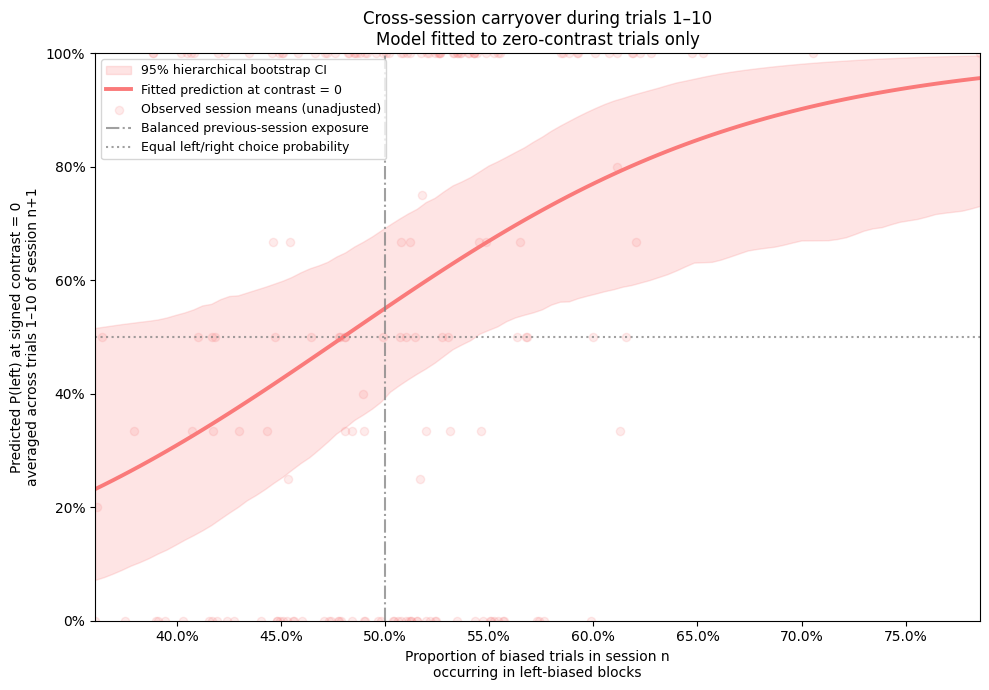

HIERARCHICAL BOOTSTRAP PREDICTION SUMMARY
Prediction contrast:     0
Trial positions:         1–10, equally weighted
Bootstrap fits used:     1000
Central 90% exposure:    0.394–0.616
Predicted P(left):       29.6%–79.7%
Probability difference:  50.1 pp
CI width at midpoint:    0.304
Bootstrap beta median:   1.014
Bootstrap beta 95% CI:   0.282 to 1.888


In [15]:
# Zero-contrast first-10 figure
# Reuse the plotting function defined in the primary analysis section.

zc_fig, zc_ax, zc_plot_data = plot_full_bootstrap_ci(
    result=result_zc,
    model=model_zc,
    data=zc10,
    boot_fe=zc_boot_fe,
    prop_grid=zc_prop_grid,
    contrast_value=0.0,
    color="#FA7A7A",
    title=(
        "Cross-session carryover during trials 1–10\n"
        "Model fitted to zero-contrast trials only"
    ),
    save_path="cross_session_prior_persistence_zero_contrast_first10.png",
    show_bootstrap_median=False,
    show_observed_sessions=True
)

All 1,000 zero-contrast bootstrap fits were retained. The median exposure coefficient was 1.014, with a 95% confidence interval [0.282, 1.888].

Across the central 90% of exposure values (`prop_left` = 0.394–0.616), fitted P(left) increased from 29.6% to 79.7%, a difference of 50.1 percentage points. These figure predictions give equal weight to positions 1–10 and set random effects to zero.

The separately printed interval [0.387, 0.686] at `prop_left` ≈ 0.498 uses observed zero-contrast trial positions and equal session weights.

### Descriptive comparison of the two fitted models

Both curves are evaluated at zero contrast, averaged equally across positions 1–10, with mouse and session random effects set to zero.

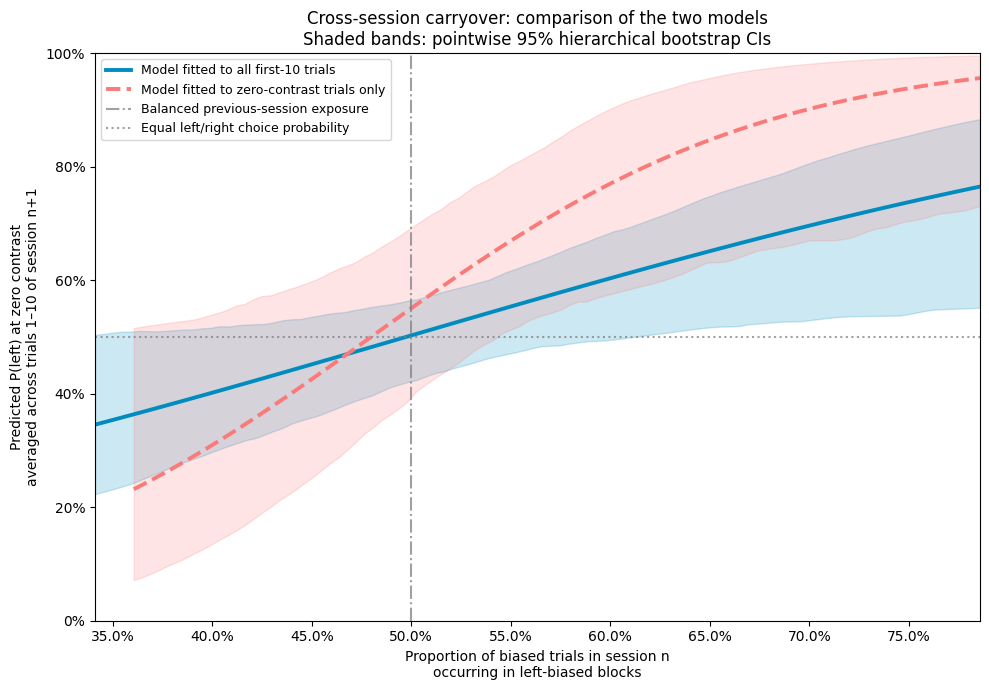

In [16]:
def plot_carryover_comparison(
    primary_prop_grid,
    primary_plot_data,
    zc_prop_grid,
    zc_plot_data,
    save_path=None
):
    """Compare existing predictions at zero contrast across trials 1–10."""
    fig, ax = plt.subplots(figsize=(10, 7))

    curves = [
        (
            primary_prop_grid,
            primary_plot_data,
            "#008CBF",
            "-",
            "Model fitted to all first-10 trials"
        ),
        (
            zc_prop_grid,
            zc_plot_data,
            "#FA7A7A",
            "--",
            "Model fitted to zero-contrast trials only"
        )
    ]

    for grid, plot_data, color, linestyle, label in curves:
        ax.fill_between(
            grid,
            plot_data["ci_low"],
            plot_data["ci_high"],
            color=color,
            alpha=0.20
        )

        ax.plot(
            grid,
            plot_data["fitted_curve"],
            color=color,
            linestyle=linestyle,
            linewidth=2.8,
            label=label
        )

    ax.axvline(
        0.5,
        color="grey",
        linestyle="-.",
        linewidth=1.5,
        alpha=0.75,
        label="Balanced previous-session exposure"
    )

    ax.axhline(
        0.5,
        color="grey",
        linestyle=":",
        linewidth=1.5,
        alpha=0.75,
        label="Equal left/right choice probability"
    )

    ax.set_xlabel(
        "Proportion of biased trials in session n\n"
        "occurring in left-biased blocks"
    )

    ax.set_ylabel(
        "Predicted P(left) at zero contrast\n"
        "averaged across trials 1–10 of session n+1"
    )

    ax.set_title(
        "Cross-session carryover: comparison of the two models\n"
        "Shaded bands: pointwise 95% hierarchical bootstrap CIs"
    )

    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))

    ax.set_xlim(
        min(np.min(primary_prop_grid), np.min(zc_prop_grid)),
        max(np.max(primary_prop_grid), np.max(zc_prop_grid))
    )
    ax.set_ylim(0, 1)
    ax.legend(loc="upper left", fontsize=9)

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    return fig, ax


# Combine the outputs from the two individual plotting calls.
comparison_fig, comparison_ax = plot_carryover_comparison(
    primary_prop_grid=primary_prop_grid,
    primary_plot_data=primary_plot_data,
    zc_prop_grid=zc_prop_grid,
    zc_plot_data=zc_plot_data,
    save_path="cross_session_carryover_model_comparison.png"
)

In [17]:
def slope_at_50(result, xname="prop_left_10"):
    b = get_fe(result, xname)

    # slope on raw prop_left scale
    return 0.25 * b / 0.10

def get_fe(result, name):
    # BinomialBayesMixedGLM results store fixed effects here
    names = result.model.exog_names
    return result.fe_mean[names.index(name)]

slope_first10 = slope_at_50(result_first10)
slope_zc = slope_at_50(result_zc)

print("Logistic slope at P(left)=0.5, all-trial model:", slope_first10)
print("Logistic slope at P(left)=0.5, zero-contrast model:", slope_zc)
print("Descriptive slope difference, zero-contrast minus all-trial:", slope_zc - slope_first10)
print("Descriptive slope ratio, zero-contrast / all-trial:", slope_zc / slope_first10)

Logistic slope at P(left)=0.5, all-trial model: 1.0246982263439677
Logistic slope at P(left)=0.5, zero-contrast model: 2.520614345817243
Descriptive slope difference, zero-contrast minus all-trial: 1.4959161194732753
Descriptive slope ratio, zero-contrast / all-trial: 2.4598601627432997


The zero-contrast model has a larger estimated exposure coefficient. The descriptive slope ratio is 2.46, calculated from the logistic derivatives at $P(\mathrm{left})=0.5$. This is a choice-probability reference point, not `prop_left = 0.5` or the slope of the trial-averaged curve. No formal between-model test was performed.

## 4. Sensitivity analyses and controls

### 4.1 Correlation between exposure and terminal direction

We calculated the exposure–terminal-direction correlation using one row per session in the primary sample and exposure values from `prop.pqt`. Odd/even biased-block counts describe the broader eligible session-$n$ pool.

In [18]:
blk = (n_pool.groupby(['session', 'block'])
       .agg(prob=('probabilityLeft', 'first'), n_trials=('probabilityLeft', 'size'))
       .reset_index())

biased = blk[blk['block'] != 1].copy()
biased['side'] = np.where(np.isclose(biased['prob'], 0.8), 1, -1)     # +1 = left-biased
biased['left_trials'] = np.where(biased['side'] == 1, biased['n_trials'], 0)

per_sess = biased.groupby('session').agg(
    n_blocks    = ('block', 'nunique'),
    first_side  = ('side', 'first'),
    last_side   = ('side', 'last'),
    left_trials = ('left_trials', 'sum'),
    tot_trials  = ('n_trials', 'sum'),
)
per_sess["prop_left"] = per_sess.index.map(prop.set_index("session")["prop_left"])
per_sess['parity']    = np.where(per_sess['n_blocks'] % 2 == 0, 'even', 'odd')

print(per_sess['parity'].value_counts())


primary_session_predictors = (first10[["session", "prop_left", "terminal_side"]].drop_duplicates("session"))

print("Primary-model sessions: corr(terminal side, prop_left):",
    round(primary_session_predictors["terminal_side"].corr(primary_session_predictors["prop_left"]),3))

parity
odd     189
even    187
Name: count, dtype: int64
Primary-model sessions: corr(terminal side, prop_left): 0.204


Exposure and terminal-block direction were modestly correlated in the primary sample ($r=0.204$). Adding terminal direction changed the exposure estimate little in the sensitivity model above.

The broader session-$n$ pool contained 189 sessions with an odd number of biased blocks and 187 with an even number.

### 4.2 Sensitivity to realised opening stimulus-side balance

For each contributing session, we calculated the proportion of nominally left-sided stimuli among responded trials at positions 1–10. We added this proportion to the primary model, centred at 0.5 and scaled per 10 percentage points.

The nominal side includes the assigned side on zero-contrast trials, where it carries no directional visual evidence.

In [19]:
# Descriptive check of realised stimulus-side balance in the exact sessions used by the model
model_sessions = first10["session"].unique()

stim_check = (n1_pool[(n1_pool.index.isin(model_sessions)) & (n1_pool["trial_number"] <= 10)]
              .groupby(level="session")
              .agg(stim_left=("stim_side", lambda s: (s == 1).mean()))
              .reset_index()
              .merge(first10[["session", "prop_left"]].drop_duplicates(), on="session", how="inner"))

print(stim_check["stim_left"].describe())
print("corr(prop_left, stim_left):", round(stim_check["prop_left"].corr(stim_check["stim_left"]), 3))

# Sensitivity check
first10_stim = (
    first10
    .drop(columns=["stim_left", "stim_left_10"], errors="ignore")
    .merge(
        stim_check[["session", "stim_left"]],
        on="session",
        how="left",
        validate="many_to_one"
    )
)

first10_stim["stim_left_10"] = (first10_stim["stim_left"] - 0.5) / 0.10

m_stim = BinomialBayesMixedGLM.from_formula(
    "chose_left ~ contrast_all + prop_left_10 + trial_c + stim_left_10",
    {"subject": "0 + C(subject)", "session": "0 + C(session)"}, first10_stim)

result_stim = m_stim.fit_vb()
print(result_stim.summary())

count    214.000000
mean       0.495327
std        0.166083
min        0.000000
25%        0.400000
50%        0.500000
75%        0.600000
max        0.800000
Name: stim_left, dtype: float64
corr(prop_left, stim_left): 0.066
                Binomial Mixed GLM Results
             Type Post. Mean Post. SD   SD  SD (LB) SD (UB)
-----------------------------------------------------------
Intercept       M     0.1683   0.0564                      
contrast_all    M     6.0019   0.3697                      
prop_left_10    M     0.3856   0.0833                      
trial_c         M    -0.3324   0.1047                      
stim_left_10    M     0.1875   0.0347                      
subject         V    -1.2936   0.1408 0.274   0.207   0.364
session         V    -0.3428   0.0483 0.710   0.644   0.782
Parameter types are mean structure (M) and variance
structure (V)
Variance parameters are modeled as log standard deviations


Across 214 sessions, mean realised left-stimulus proportion was 0.495, with a small correlation with previous-session exposure ($r=0.066$).

After adjustment, the exposure coefficient was $\beta=0.386$ (posterior SD = 0.083; 95% variational interval [0.222, 0.549]), corresponding to an odds ratio of 1.47 [1.25, 1.73]. This was close to the primary estimate of 0.410.

### 4.3 Within-mouse permutation test

We shuffled session-level exposure values within mice 1,000 times, assigning each shuffled value to all trials in its session. The test statistic was the exposure coefficient from a binomial logistic GLM with signed contrast, trial position, and mouse fixed effects.

The two-sided p-value compares absolute shuffled and observed coefficients, with a plus-one correction. This test assumes exchangeable session exposure labels within mice under the null.

Observed permutation statistic: 0.387
Null mean: -0.007
Null SD: 0.120
Two-sided permutation p-value: 0.0030


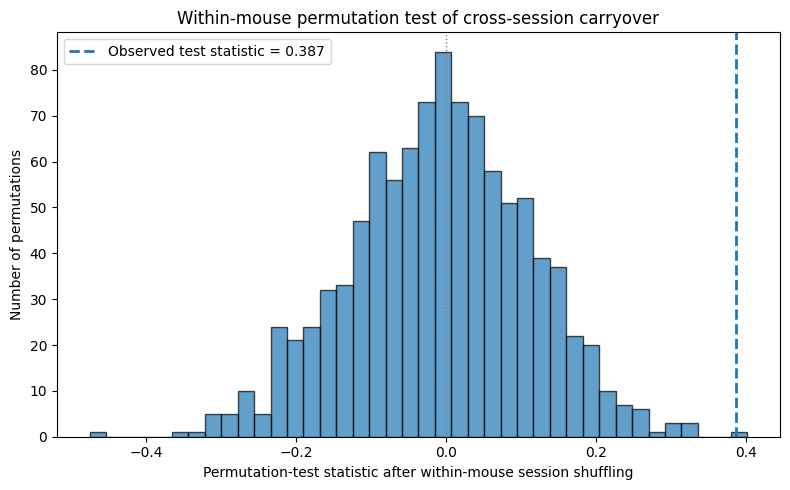

In [20]:

perm_trials = first10.copy()
session_info = perm_trials[["session", "subject", "prop_left"]].drop_duplicates().reset_index(drop=True)

assert session_info["session"].is_unique

observed_fit = smf.glm("chose_left ~ contrast_all + prop_left_10 + trial_c + C(subject)",
                       data=perm_trials, family=sm.families.Binomial()).fit()

observed_statistic = observed_fit.params["prop_left_10"]

rng = np.random.default_rng(42)
n_permutations = 1000
null_statistics = np.empty(n_permutations)

for i in range(n_permutations):
    shuffled_sessions = session_info.copy()
    shuffled_sessions["prop_left_shuffled"] = shuffled_sessions.groupby("subject")["prop_left"].transform(
        lambda x: rng.permutation(x.to_numpy()))
    shuffled_map = shuffled_sessions.set_index("session")["prop_left_shuffled"]
    perm_trials["prop_left_10_shuffled"] = (perm_trials["session"].map(shuffled_map) - 0.5) / 0.10
    shuffled_fit = smf.glm("chose_left ~ contrast_all + prop_left_10_shuffled + trial_c + C(subject)",
                           data=perm_trials, family=sm.families.Binomial()).fit()
    null_statistics[i] = shuffled_fit.params["prop_left_10_shuffled"]

permutation_p = (1 + np.sum(np.abs(null_statistics) >= np.abs(observed_statistic))) / (n_permutations + 1)
perm_trials.drop(columns="prop_left_10_shuffled", inplace=True)

print(f"Observed permutation statistic: {observed_statistic:.3f}")
print(f"Null mean: {null_statistics.mean():.3f}")
print(f"Null SD: {null_statistics.std():.3f}")
print(f"Two-sided permutation p-value: {permutation_p:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(null_statistics, bins=40, edgecolor="black", alpha=0.7)
ax.axvline(observed_statistic, linestyle="--", linewidth=2,
           label=f"Observed test statistic = {observed_statistic:.3f}")
ax.axvline(0, color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("Permutation-test statistic after within-mouse session shuffling")
ax.set_ylabel("Number of permutations")
ax.set_title("Within-mouse permutation test of cross-session carryover")
ax.legend()
plt.tight_layout()
plt.show()

The observed coefficient was 0.387; shuffled coefficients had a mean of −0.007 and an SD of 0.120. The association was unusual under within-mouse session shuffling ($p=0.0030$).

### 4.4 Within-session positive control

The positive control uses established biased-block trials from the broader eligible session-$n$ pool. We excluded the opening block and the first 10 positions of each biased block.

The binomial mixed-effects model includes signed contrast and block context, with mouse and session random intercepts. Context is coded as +0.5 for left-biased and −0.5 for right-biased blocks, so its coefficient represents the full contrast between block types. This fit uses `gtol=1e-4`.

Zero-contrast predictions set both random effects to zero.

In [21]:
# Use established biased-block trials
late = n_pool.reset_index()
late = late[(late["block"] != 1) & (late["trial_in_block"] > 10)].copy()

late["chose_left"] = (late["choice"] == 1).astype(int)
late["block_side_c"] = np.where(np.isclose(late["probabilityLeft"], 0.8), 0.5, -0.5)
late["block_label"] = np.where(late["block_side_c"] == 0.5, "Left-biased block", "Right-biased block")

# Raw choice proportions are descriptive because stimulus distributions differ between block types
raw_control = late.groupby("block_label")["chose_left"].agg(mean_left_choice="mean", n_trials="size")
print(raw_control)

control_model = BinomialBayesMixedGLM.from_formula(
    "chose_left ~ contrast_all + block_side_c",
    {"subject": "0 + C(subject)", "session": "0 + C(session)"},late)

control_result = control_model.fit_vb(minim_opts={"gtol": 1e-4})
print(control_result.summary())

control_effects = pd.DataFrame(
    {"estimate": control_result.fe_mean, "posterior_sd": control_result.fe_sd},
    index=control_model.exog_names
)
control_effects["ci_low"] = control_effects["estimate"] - 1.96 * control_effects["posterior_sd"]
control_effects["ci_high"] = control_effects["estimate"] + 1.96 * control_effects["posterior_sd"]
control_effects["odds_ratio"] = np.exp(control_effects["estimate"])
control_effects["or_low"] = np.exp(control_effects["ci_low"])
control_effects["or_high"] = np.exp(control_effects["ci_high"])

display(control_effects.loc[["block_side_c"]])

control_coef = pd.Series(
    control_result.fe_mean,
    index=control_model.exog_names
)

for label, block_value in [
    ("Left-biased block", 0.5),
    ("Right-biased block", -0.5)
]:
    prediction = expit(
        control_coef["Intercept"]
        + control_coef["block_side_c"] * block_value
    )
    print(f"{label}: predicted P(left) at zero contrast = {prediction:.1%}")

                    mean_left_choice  n_trials
block_label                                   
Left-biased block           0.782531    105206
Right-biased block          0.236851    105066
                Binomial Mixed GLM Results
             Type Post. Mean Post. SD   SD  SD (LB) SD (UB)
-----------------------------------------------------------
Intercept       M     0.0512   0.0063                      
contrast_all    M     7.1262   0.0489                      
block_side_c    M     1.9370   0.0127                      
subject         V    -4.1316   0.1495 0.016   0.012   0.022
session         V    -0.1030   0.0364 0.902   0.839   0.970
Parameter types are mean structure (M) and variance
structure (V)
Variance parameters are modeled as log standard deviations


,estimate,posterior_sd,ci_low,ci_high,odds_ratio,or_low,or_high
block_side_c,1.936977,0.012688,1.912109,1.961845,6.937746,6.767346,7.112437


Left-biased block: predicted P(left) at zero contrast = 73.5%
Right-biased block: predicted P(left) at zero contrast = 28.6%


The positive-control dataset contained 210,272 trials. Raw left-choice proportions were 78.3% in left-biased blocks (105,206 trials) and 23.7% in right-biased blocks (105,066 trials); these also reflect the different stimulus distributions.

After adjustment for signed contrast, the block-context coefficient was $\beta=1.937$ (posterior SD = 0.013; 95% variational interval [1.912, 1.962]), with an odds ratio of 6.94 [6.77, 7.11]. Predicted P(left) at zero contrast was 73.5% in left-biased blocks and 28.6% in right-biased blocks.

## 5. Conclusion

Across 214 consecutive session pairs from 26 mice, greater left-biased exposure in the preceding session was associated with more left choices during the next session's first 10 unbiased trials. Per 10-percentage-point increase in exposure, the primary model gave an odds ratio of 1.51 [1.28, 1.77]; the zero-contrast model gave 2.74 [1.85, 4.05]. These are approximate 95% variational posterior intervals.

The exposure estimate remained similar after adjustment for terminal-block direction and realised stimulus-side balance, and when allowing mouse-specific exposure slopes. The paired terminal-direction comparison was not statistically significant ($p=0.233$).

Bootstrap coefficient intervals were above zero in both analyses, and the within-mouse permutation check supported the association ($p=0.0030$). The positive control detected a block-context association during established biased blocks.

These observational findings are consistent with cross-session carryover into opening choices. Changes across the full 90-trial opening block are examined separately.